# Lohmann_Exploration.ipynb
**ICS 3202 — Artificial Intelligence | Project Deliverable 1**

**Project:** An Integrated ERP System for Poultry Farm Management

**Dataset:** [Lohmann Brown-Classic laying hens in Colombia](https://data.mendeley.com/datasets/t2gzbht99m)
(Cabezas-García et al., 2024, Mendeley Data, CC BY 4.0): weekly records of 9 commercial flocks of about 1,500 hens, 2003–2015.

**Output variable:** the flock's **laying rate** (% of hens laying per day), forecast 1, 4 and 8 weeks ahead.

## Datasets considered

| Dataset | Source | Output variable |
|---|---|---|
| **Lohmann Brown-Classic flock records** (selected) | Mendeley Data `t2gzbht99m` | weekly laying rate per flock |
| Egg Producing Chickens | Kaggle `phuzoman/egg-producing-chickens` | eggs per day per hen |
| Prediction of Egg Production Rate in Poultry | Kaggle `deepikabidri/prediction-of-egg-production-rate-in-poultry` | production level |
| Environmental Effect on Egg Production | Kaggle `faysal1998/environmental-effect-on-egg-production` | total eggs |

## Load the data

In [1]:
# In Colab, fetch the project first (the data file and the ml_engine code)
import os
if not os.path.exists('ml_engine'):
    !git clone -q https://github.com/alfredmuriu/SemProject_MLEngine.git
    %cd SemProject_MLEngine

import pandas as pd

df = pd.read_csv('data/lohmann_brown_flocks.txt', sep='\t')
df.head()

,Year,Generation,Flock,WeekOld,ProdWeek,HousedHens,BirdsBalance,NumberEggsPerWeek,FeedPerWeek,MortalityCullingRateWeek,...,LayingRateDay,IdealLayingRateDay,LayingRateHenHoused,IdealLayingRateHenHoused,FeedConvertionPerDozenEggs,NEggsHenWeek,CummNEggsHen,NEggsHenHousedWeek,CummNEggsHenHousedWeek,IdealCummNEggsHenHousedWeek
0,2003.0,1.0,1.0,20.0,1.0,1548.0,1548.0,4.0,930.81,0.0,...,0.04,40.0,0.04,40.0,2792.44,0.00,0.00,0.00,0.00,3.9
1,2003.0,1.0,1.0,21.0,2.0,1548.0,1548.0,17.0,934.50,0.0,...,0.16,60.1,0.16,60.0,659.64,0.01,0.01,0.01,0.01,8.1
2,2003.0,1.0,1.0,22.0,3.0,1548.0,1548.0,148.0,937.86,0.0,...,1.37,75.2,1.37,75.0,76.04,0.10,0.11,0.10,0.11,13.3
3,2003.0,1.0,1.0,23.0,4.0,1548.0,1548.0,606.0,937.86,0.0,...,5.59,85.3,5.59,85.0,18.57,0.39,0.50,0.39,0.50,19.3
4,2003.0,1.0,1.0,24.0,5.0,1548.0,1548.0,1864.0,977.95,0.0,...,17.20,90.5,17.20,90.0,6.30,1.20,1.70,1.20,1.70,25.6


## a. How many rows and columns are contained in the dataset? (3 marks)

In [2]:
num_rows, num_cols = df.shape
print("Rows:", num_rows)
print("Columns:", num_cols)

Rows: 469
Columns: 22


## b. What datatypes are contained in the dataset? (3 marks)

In [3]:
df.dtypes

Year                           float64
Generation                     float64
Flock                          float64
WeekOld                        float64
ProdWeek                       float64
HousedHens                     float64
BirdsBalance                   float64
NumberEggsPerWeek              float64
FeedPerWeek                    float64
MortalityCullingRateWeek       float64
CummMortalityCullingRate       float64
FeedIntake                     float64
LayingRateDay                  float64
IdealLayingRateDay                 str
LayingRateHenHoused            float64
IdealLayingRateHenHoused           str
FeedConvertionPerDozenEggs     float64
NEggsHenWeek                   float64
CummNEggsHen                   float64
NEggsHenHousedWeek             float64
CummNEggsHenHousedWeek         float64
IdealCummNEggsHenHousedWeek        str
dtype: object

All columns are numbers except `IdealLayingRateDay`, which contains a non-number (see part c).

## c. Is the dataset complete? i.e. no missing values? (2 marks)

In [4]:
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())

Year                           1
Generation                     1
Flock                          1
WeekOld                        1
ProdWeek                       1
HousedHens                     1
BirdsBalance                   1
NumberEggsPerWeek              1
FeedPerWeek                    1
MortalityCullingRateWeek       1
CummMortalityCullingRate       1
FeedIntake                     1
LayingRateDay                  1
IdealLayingRateDay             1
LayingRateHenHoused            1
IdealLayingRateHenHoused       1
FeedConvertionPerDozenEggs     1
NEggsHenWeek                   1
CummNEggsHen                   1
NEggsHenHousedWeek             1
CummNEggsHenHousedWeek         1
IdealCummNEggsHenHousedWeek    1
dtype: int64

Total missing values: 22


**Not quite.** There is one completely empty row (the blank last line of the file), and the breed-standard column has a `"."` at week 71
for two flocks. Both are dealt with in the cleaning below.

## d. Slice out the first 15 rows and last 20 rows, merge into `df_sample`, display it (4 marks)

In [5]:
df_sample = pd.concat([df.head(15), df.tail(20)], ignore_index=True)
df_sample

,Year,Generation,Flock,WeekOld,ProdWeek,HousedHens,BirdsBalance,NumberEggsPerWeek,FeedPerWeek,MortalityCullingRateWeek,...,LayingRateDay,IdealLayingRateDay,LayingRateHenHoused,IdealLayingRateHenHoused,FeedConvertionPerDozenEggs,NEggsHenWeek,CummNEggsHen,NEggsHenHousedWeek,CummNEggsHenHousedWeek,IdealCummNEggsHenHousedWeek
0,2003.0,1.0,1.0,20.0,1.0,1548.0,1548.0,4.0,930.81,0.00,...,0.04,40.0,0.04,40.0,2792.44,0.00,0.00,0.00,0.00,3.9
1,2003.0,1.0,1.0,21.0,2.0,1548.0,1548.0,17.0,934.50,0.00,...,0.16,60.1,0.16,60.0,659.64,0.01,0.01,0.01,0.01,8.1
2,2003.0,1.0,1.0,22.0,3.0,1548.0,1548.0,148.0,937.86,0.00,...,1.37,75.2,1.37,75.0,76.04,0.10,0.11,0.10,0.11,13.3
3,2003.0,1.0,1.0,23.0,4.0,1548.0,1548.0,606.0,937.86,0.00,...,5.59,85.3,5.59,85.0,18.57,0.39,0.50,0.39,0.50,19.3
4,2003.0,1.0,1.0,24.0,5.0,1548.0,1548.0,1864.0,977.95,0.00,...,17.20,90.5,17.20,90.0,6.30,1.20,1.70,1.20,1.70,25.6
5,2003.0,1.0,1.0,25.0,6.0,1548.0,1547.0,3852.0,1048.38,0.06,...,35.57,92.6,35.55,92.0,3.27,2.49,4.19,2.49,4.19,32.0
6,2003.0,1.0,1.0,26.0,7.0,1548.0,1546.0,6253.0,1137.05,0.06,...,57.78,93.2,57.71,92.6,2.18,4.04,8.24,4.04,8.23,38.5
7,2003.0,1.0,1.0,27.0,8.0,1548.0,1546.0,7575.0,1190.42,0.00,...,70.00,93.8,69.91,92.8,1.89,4.90,13.14,4.89,13.13,45.0
8,2003.0,1.0,1.0,28.0,9.0,1548.0,1545.0,9002.0,1190.42,0.06,...,83.24,93.8,83.07,93.0,1.59,5.83,18.97,5.82,18.94,51.5
9,2003.0,1.0,1.0,29.0,10.0,1548.0,1545.0,9535.0,1226.75,0.00,...,88.16,93.9,87.99,92.8,1.54,6.17,25.14,6.16,25.10,58.0


## Data cleaning

1. Remove the empty row and check for duplicates.
2. Keep only what a farmer records each week: flock, age, hens alive, eggs, feed (whole flock, kg).
   Columns such as the laying rate are calculated from the eggs, so they are recalculated rather than used as inputs.
3. Work out deaths each week as the drop in hens alive.
4. Recalculate the laying rate: eggs ÷ (7 × hens) × 100.

In [6]:
before = df.shape
df = df.dropna(how='all')                                   # 1. the empty row
print("Duplicates:", df.duplicated().sum())

clean = pd.DataFrame({                                      # 2. what a farmer records
    'flock': 'G' + df['Generation'].astype(int).astype(str) + '-F' + df['Flock'].astype(int).astype(str),
    'age_weeks': df['WeekOld'].astype(int),
    'hens': df['BirdsBalance'].astype(int),
    'eggs': df['NumberEggsPerWeek'].astype(int),
    'feed_kg': df['FeedPerWeek'],
})
previous_hens = clean.groupby('flock')['hens'].shift(1).fillna(df['HousedHens'])
clean['deaths'] = (previous_hens - clean['hens']).astype(int)     # 3. deaths
clean['lay_rate'] = 100 * clean['eggs'] / (7 * clean['hens'])     # 4. laying rate

print("Before:", before, " After:", clean.shape)
clean.head()

Duplicates: 0
Before: (469, 22)  After: (468, 7)


,flock,age_weeks,hens,eggs,feed_kg,deaths,lay_rate
0,G1-F1,20,1548,4,930.81,0,0.036914
1,G1-F1,21,1548,17,934.50,0,0.156884
2,G1-F1,22,1548,148,937.86,0,1.365818
3,G1-F1,23,1548,606,937.86,0,5.592470
4,G1-F1,24,1548,1864,977.95,0,17.201920


The cleaned data is also in `data/cleaned_dataset.xlsx`, and the original in `data/original_dataset.xlsx`.

## Every flock's laying rate against the breed standard

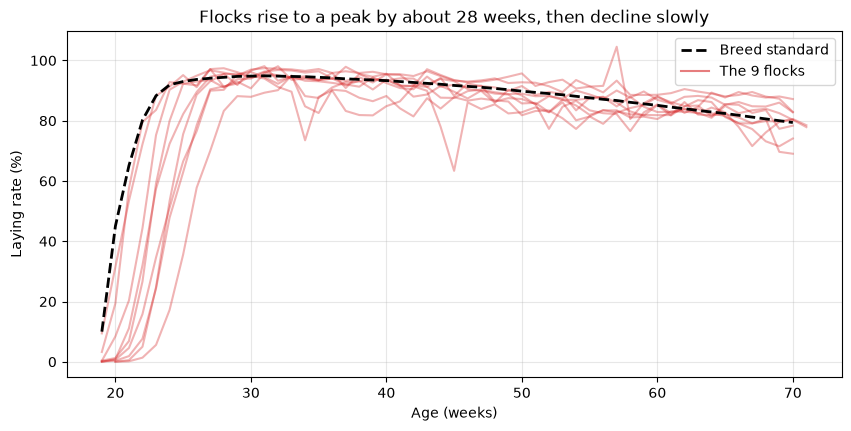

In [7]:
import matplotlib.pyplot as plt

standard = pd.to_numeric(df[df['Generation'] == 3]['IdealLayingRateDay']).groupby(df['WeekOld']).median()

fig, ax = plt.subplots(figsize=(10, 4.5))
for flock, rows in clean.groupby('flock'):
    ax.plot(rows['age_weeks'], rows['lay_rate'], color='tab:red', alpha=0.35)
ax.plot(standard.index, standard.values, 'k--', linewidth=2, label='Breed standard')
ax.plot([], [], color='tab:red', alpha=0.6, label='The 9 flocks')
ax.set_xlabel('Age (weeks)'); ax.set_ylabel('Laying rate (%)')
ax.set_title('Flocks rise to a peak by about 28 weeks, then decline slowly')
ax.legend(); ax.grid(alpha=0.3); plt.show()

- Flocks start laying at different times, so the start of lay is the hardest part to predict.
- After the peak, laying declines slowly, with occasional sudden dips.
- Most flocks fall below the breed standard at some point, which is what the ERP needs to warn about.